# RT-DETR-L · Query-based detection

**Assignment:** Query-based detector. This notebook prepares the data, trains three RT-DETR-L configurations for 8 epochs each, backs up checkpoints to Hugging Face, and plots validation curves.

Both the training set and the monitoring validation set are sampled every 5th frame per video sequence. The final COCO evaluation uses every 5th frame of the original validation split (`step=5`, no tiling).

| Experiment | Queries | Hungarian matcher class / bbox / GIoU | Epochs |
|---|---:|---|---:|
| `reference_step5` | 300 | 2 / 5 / 2 | 8 |
| `queries200_step5` | 200 | 2 / 5 / 2 | 8 |
| `matching_step5` | 300 | 2 / 7 / 3 | 8 |

All three runs start from the same COCO-pretrained `rtdetr-l.pt` weights and use the same optimizer, learning rate (1e-5), image size (640) and batch size (1). Each run has its own Hugging Face backup path.

The results are compared with 12 saved RetinaNet epochs on the same validation images. Equal epoch counts do not imply equal GPU time.

## 1. Parameters — edit only this cell

All core settings are together. Set `RUN_TRAINING=False` to re-create figures/evaluation from existing step-5 checkpoints on Hugging Face. Keep `STEP=5` for both training and COCO evaluation.

In [1]:
STEP = 5
EPOCHS = 8
IMGSZ = 640
BATCH = 1
LR = 1e-5
OPTIMIZER = 'AdamW'
SEED = 42
MONITOR_VAL_STEP = STEP
EVAL_STEP = STEP
EVAL_TILE = 0
EVAL_CONF = 0.01
EVAL_IMGSZ = 640
RUN_PREP = True
RUN_TRAINING = True            # New step-5 training: reference, 200 queries, modified matching
RUN_COCO_EVAL = True           # Exact same step-5 original validation frames for all three
UPLOAD_HF = True              # Checkpoints/results sent to distinct step-5 folders
REUSE_EXISTING_HF_RUNS = True # Completed runs are downloaded instead of trained again
START_MODE = 'coco'           # 'coco' (recommended) or 'old_finetune' (not a clean step-5 protocol)
RUN_NAMES = ['reference_step5', 'queries200_step5', 'matching_step5']
EXPERIMENTS = {
    'reference_step5': {'queries':300, 'matching':{'class':2,'bbox':5,'giou':2}},
    'queries200_step5': {'queries':200, 'matching':{'class':2,'bbox':5,'giou':2}},
    'matching_step5': {'queries':300, 'matching':{'class':2,'bbox':7,'giou':3}},
}
assert STEP == EVAL_STEP == MONITOR_VAL_STEP == 5, 'This notebook is designed for step=5 throughout'
assert START_MODE in ('coco','old_finetune')
# RetinaNet epoch checkpoints: compare old step-5 baseline against NEW RT-DETR runs.
RUN_RETINANET_EPOCH_EVAL = True
RETINANET_EPOCHS_TO_EVAL = list(range(1, 13))  # all twelve historical checkpoints
RUN_RTDETR_EPOCH_COCO = True                 # evaluate all 8 epochs of tuned RT-DETR
RTDETR_CURVE_RUN = 'matching_step5'          # fixed choice, not picked after seeing final COCO results
COMPARISON_EPOCH_LIMIT = EPOCHS                   # epoch-count comparison WINDOW, not equal GPU time/FLOPs
assert RTDETR_CURVE_RUN in RUN_NAMES


## 2. Install, clone, and authorize

Installs dependencies (Ultralytics 8.4.210), clones the project repository and authenticates to Hugging Face using the HF_TOKEN Kaggle secret.

In [2]:
import os,sys,subprocess,json,time,shutil,zipfile,traceback
from pathlib import Path
subprocess.run([sys.executable,'-m','pip','install','-q','ultralytics==8.4.210','huggingface_hub','pycocotools','pandas','matplotlib','pyyaml'],check=True)
import torch, pandas as pd, matplotlib.pyplot as plt, ultralytics
from huggingface_hub import HfApi, hf_hub_download
from kaggle_secrets import UserSecretsClient
from IPython.display import display
assert ultralytics.__version__=='8.4.210',ultralytics.__version__
assert torch.cuda.is_available(),'Enable GPU in Kaggle settings'
HF_TOKEN = UserSecretsClient().get_secret('HF_TOKEN').strip()
assert HF_TOKEN, 'Enable secret HF_TOKEN for this new notebook'
os.environ['HF_TOKEN']=HF_TOKEN
api=HfApi(token=HF_TOKEN)
HF_REPO='lilialania/visdrone-retinanet'
print('HF account:',api.whoami()['name'])
api.repo_info(repo_id=HF_REPO,repo_type='model',token=HF_TOKEN)
DATA_ROOT=Path('/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026')
REPO=Path('/kaggle/working/drone-multi-object-detection')
REPO_URL='https://github.com/lilialania/drone-multi-object-detection.git'
WORK=Path('/kaggle/working/query_based_step5')
SUBSET=WORK/'subset_step5'; RUNS=WORK/'runs'; EVAL_OUT=WORK/'coco_eval_step5'
for p in (WORK,RUNS,EVAL_OUT):p.mkdir(parents=True,exist_ok=True)
assert (DATA_ROOT/'train'/'annotations_coco.json').is_file(), 'Competition dataset is not attached'
assert (DATA_ROOT/'val'/'annotations_coco.json').is_file(), 'Validation annotations missing'
if not (REPO/'src'/'make_subset.py').is_file():
    subprocess.run(['git','clone',REPO_URL,str(REPO)],check=True)
sys.path.insert(0,str(REPO)); os.chdir(REPO)
from ultralytics import RTDETR
print('GPU:',torch.cuda.get_device_name(0),'Ultralytics:',ultralytics.__version__)
print('Repository:',REPO,'Data:',DATA_ROOT)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
HF account: lilialania


Cloning into '/kaggle/working/drone-multi-object-detection'...


GPU: Tesla T4 Ultralytics: 8.4.210
Repository: /kaggle/working/drone-multi-object-detection Data: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026


## 3. Build exactly every 5th frame (train **and** monitoring val)

`src.data.make_subset` selects every fifth frame **inside each video sequence**, keeping train and validation splits separate. The full official validation annotations remain untouched for COCO evaluation.

In [3]:
from src.data.data_utils import CLASS_NAMES, image_path_for, load_coco, subsampled_frame_list
from src.data.make_subset import _annotation_path
from pycocotools.coco import COCO
if RUN_PREP and not (SUBSET/'data.yaml').is_file():
    # Equivalent to src.data.make_subset selection/conversion but NO huge duplicate ZIP.
    import yaml
    for split in ('train','val'):
        splitroot=DATA_ROOT/split
        frames,_=load_coco(splitroot/'annotations_coco.json',split)
        selected=subsampled_frame_list(frames,STEP)
        for j,item in enumerate(selected):
            src=image_path_for(splitroot,item['file_name'])
            clip=str(item['clip'])
            dest=SUBSET/'images'/split/clip/src.name
            dest.parent.mkdir(parents=True,exist_ok=True);shutil.copy2(src,dest)
            for folder,required in (('labels',True),('ignore',False)):
                labelsrc=_annotation_path(splitroot,item['file_name'],folder)
                labeldst=SUBSET/folder/split/clip/(src.stem+'.txt')
                if labelsrc.is_file():
                    labeldst.parent.mkdir(parents=True,exist_ok=True)
                    shutil.copy2(labelsrc,labeldst)
                elif required:raise FileNotFoundError(labelsrc)
            if (j+1)%1500==0:print('Prepared',split,j+1,'of',len(selected),flush=True)
    yamlconfig={'path':str(SUBSET),'train':'images/train','val':'images/val',
                'names':{i:name for i,name in enumerate(CLASS_NAMES)}}
    (SUBSET/'data.yaml').write_text(yaml.safe_dump(yamlconfig,sort_keys=False,allow_unicode=True),encoding='utf-8')
assert (SUBSET/'data.yaml').is_file(), 'Subset missing; enable RUN_PREP'
# YAML absolute root (avoids path: . relative-to-process issues)
import yaml
config=yaml.safe_load((SUBSET/'data.yaml').read_text())
config['path']=str(SUBSET)
TRAIN_YAML=WORK/'step5_data.yaml'
TRAIN_YAML.write_text(yaml.safe_dump(config,sort_keys=False,allow_unicode=True),encoding='utf-8')
def count_images(p):return sum(x.suffix.lower() in {'.jpg','.jpeg','.png'} for x in p.rglob('*') if x.is_file())
train_n=count_images(SUBSET/'images'/'train')
monitor_n=count_images(SUBSET/'images'/'val')
coco=COCO(str(DATA_ROOT/'val'/'annotations_coco.json'))
EVAL_IDS=sorted(coco.getImgIds())[::EVAL_STEP]
print('Training frames (step 5):',train_n)
print('Monitoring validation frames (step 5):',monitor_n)
print('Original val COCO frames evaluated (step 5):',len(EVAL_IDS))
print('Training YAML:',TRAIN_YAML)
assert train_n>0 and monitor_n>0 and EVAL_IDS

Prepared train 1500 of 4868
Prepared train 3000 of 4868
Prepared train 4500 of 4868
loading annotations into memory...
Done (t=0.46s)
creating index...
index created!
Training frames (step 5): 4868
Monitoring validation frames (step 5): 571
Original val COCO frames evaluated (step 5): 570
Training YAML: /kaggle/working/query_based_step5/step5_data.yaml


## 4. Check the GT labels visually

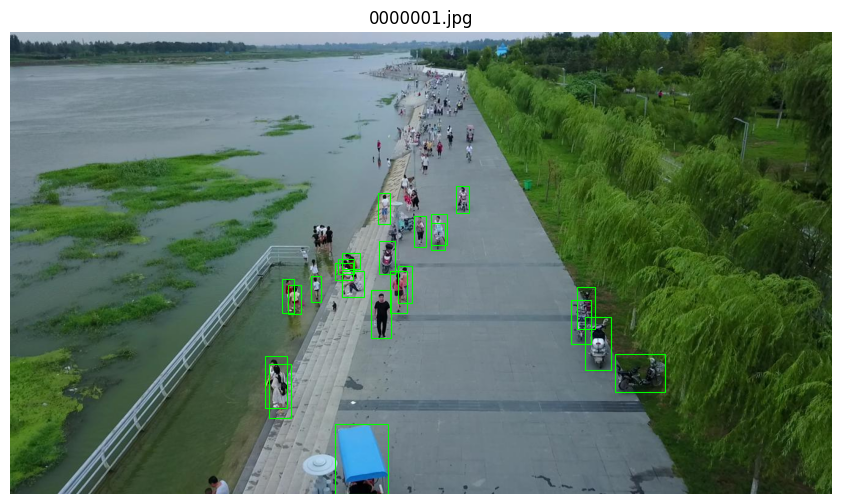

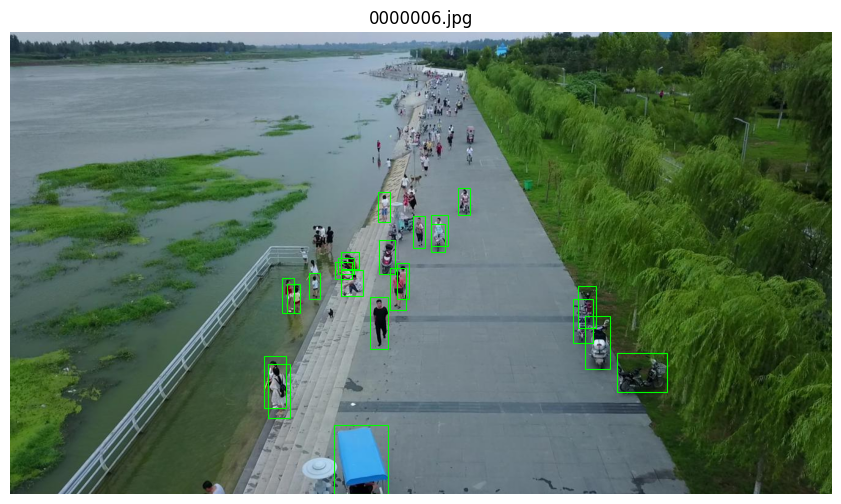

In [4]:
from PIL import Image
from matplotlib.patches import Rectangle
samples=sorted((SUBSET/'images'/'train').rglob('*.jpg'))[:2]
for imgp in samples:
    labelp=(SUBSET/'labels'/'train'/imgp.relative_to(SUBSET/'images'/'train')).with_suffix('.txt')
    im=Image.open(imgp).convert('RGB'); w,h=im.size
    fig,ax=plt.subplots(figsize=(11,6));ax.imshow(im)
    if labelp.is_file():
        for row in labelp.read_text().splitlines():
            vals=list(map(float,row.split()))
            if len(vals)!=5:continue
            cl,cx,cy,bw,bh=vals
            ax.add_patch(Rectangle(((cx-bw/2)*w,(cy-bh/2)*h),bw*w,bh*h,fill=False,ec='lime',lw=.8))
    ax.set_title(imgp.name);ax.axis('off');plt.show();plt.close(fig)

## 5. Model theory, the two tuned parameters, and validity

**Query-based RT-DETR:** a CNN backbone extracts visual features, a transformer decoder predicts a fixed number of object queries, each with a class and box. **Hungarian bipartite matching** assigns each ground-truth object to at most one query using a class/box/GIoU cost. Unmatched predictions contribute to the classification objective, encouraging **one prediction per object**. Therefore native single-image RT-DETR uses **no conventional NMS**; in this notebook `tile=0`, so there is also no cross-tile NMS (tiling would need merging). Matching needs global assignment and can be harder to optimize initially than dense CNN supervision; with few epochs, a plateau is evidence of incomplete convergence, not a proof that Transformers are inferior.

**Density:** 200 queries cap the *number of distinct candidate detections* below 300; in dense videos, crowding and small box scale reduce recall. The theoretical query ceiling is not a direct bound on quality, and reduced queries can still have better precision.

**Parameter search (3 experiments):** 200 or 300 decoder object queries; matcher class=2, bbox=5 or 7, GIoU=2 or 3. Same COCO-pretrained start, 8 epochs, LR 1e-5, AdamW, 640 px, batch 1. **Auxiliary/denoising** remain on the Ultralytics defaults; this is *not* an ablation of those losses. We alter the matcher cost, not the overall loss weights.

**Control:** epoch count, optimizer and training images are matched across the three RT-DETR configurations. The RetinaNet checkpoints were trained earlier with a different budget, so the comparison with them is matched by validation images and metrics, not by compute.

## 6. Training implementation — safe tuning, per-epoch HF backups

We change matcher cost via a class-level temporary patch and query count through a custom RTDETRTrainer. A clear integrity check confirms both modifications before training.

On Kaggle restarts, finished runs are fetched from Hugging Face and skipped. An interrupted run can be recovered from its latest `epoch_XX.pt`, but the saved epoch file is a checkpoint of model state; a proper optimizer/scheduler continuation should use the corresponding `last.pt` with `resume=True` and the same training configuration.

In [5]:
from ultralytics.models.rtdetr.train import RTDETRTrainer
from ultralytics.nn.tasks import RTDETRDetectionModel
from ultralytics.models.utils.ops import HungarianMatcher

# Monkeypatch the matcher CLASS constructor only while the specific run trains.
# No bound method is added to a model instance, so the saved checkpoint is portable.
_MATCHER_INIT=HungarianMatcher.__init__
_ACTIVE_MATCHING=None
_ACTIVE_QUERIES=None

def tuned_matcher_init(self, cost_gain=None, *args, **kwargs):
    gains=dict(_ACTIVE_MATCHING) if _ACTIVE_MATCHING else cost_gain
    return _MATCHER_INIT(self,cost_gain=gains,*args,**kwargs)

class Step5RTDETRTrainer(RTDETRTrainer):
    def get_model(self, cfg=None, weights=None, verbose=True):
        model=super().get_model(cfg=cfg,weights=weights,verbose=verbose)
        head=model.model[-1]
        assert hasattr(head,'num_queries'), 'Unknown RT-DETR decoder API; abort rather than silently ignore tuning'
        assert _ACTIVE_QUERIES in (200,300), 'Set active query configuration first'
        head.num_queries=int(_ACTIVE_QUERIES)
        print('CONFIRMED decoder num_queries:',head.num_queries)
        return model

REMOTE_PREFIX='query_rtdetr_step5_clean_coco_8epochs'
def remote(name,file):return f'{REMOTE_PREFIX}/{name}/{file}'
def hf_exists(name,file):
    return api.file_exists(repo_id=HF_REPO,filename=remote(name,file),repo_type='model',token=HF_TOKEN)
def hf_get(name,file):
    return Path(hf_hub_download(repo_id=HF_REPO,filename=remote(name,file),repo_type='model',token=HF_TOKEN))
def hf_put(src,name,file):
    if UPLOAD_HF and Path(src).is_file():
        api.upload_file(path_or_fileobj=str(src),path_in_repo=remote(name,file),repo_id=HF_REPO,
                        repo_type='model',token=HF_TOKEN,
                        commit_message=f'RT-DETR-L step5 {name}: {file}')

if START_MODE=='coco':
    START_WEIGHTS='rtdetr-l.pt'
else:
    START_WEIGHTS=str(hf_hub_download(repo_id=HF_REPO,filename='query_rtdetr/finetune_safe/weights/best.pt',
                                      repo_type='model',token=HF_TOKEN))
print('Common starting weights:',START_WEIGHTS)

Common starting weights: rtdetr-l.pt


### Run all three configurations in a single cell

Each configuration is a separate 8-epoch fine-tuning run starting from the same COCO-pretrained weights; the second and third runs do not initialize from the first. If Hugging Face already holds a `best.pt` for a run in the step-5 prefix, that run is skipped. Per-epoch checkpoints and the training CSV are backed up to Hugging Face.

In [6]:
RUN_STATUS={}
TRAIN_TIMES={}
for run_name in RUN_NAMES:
    cfg=EXPERIMENTS[run_name]
    run_dir=RUNS/run_name
    run_dir.mkdir(parents=True,exist_ok=True)
    expected_config={'name':run_name,'step':STEP,'epochs':EPOCHS,'start_mode':START_MODE,
                     'start_weights':START_WEIGHTS if START_MODE=='coco' else 'old_finetune',
                     'queries':cfg['queries'],'matching':cfg['matching'], 'imgsz':IMGSZ,
                     'batch':BATCH,'lr0':LR,'optimizer':OPTIMIZER,'seed':SEED,'ultralytics':ultralytics.__version__}
    configpath=run_dir/'experiment_config.json'
    if REUSE_EXISTING_HF_RUNS and hf_exists(run_name,'weights/best.pt') and hf_exists(run_name,'results.csv'):
        if hf_exists(run_name,'experiment_config.json'):
            old=json.loads(hf_get(run_name,'experiment_config.json').read_text())
            assert {k:old.get(k) for k in ('step','epochs','start_mode','queries','matching','imgsz','batch','lr0','optimizer')} == {k:expected_config[k] for k in ('step','epochs','start_mode','queries','matching','imgsz','batch','lr0','optimizer')}, f'HF config mismatch for {run_name}: change REMOTE_PREFIX'
        for file in ['weights/best.pt','results.csv']:
            dest=run_dir/file;dest.parent.mkdir(parents=True,exist_ok=True)
            shutil.copy2(hf_get(run_name,file),dest)
        RUN_STATUS[run_name]='reused_complete_hf'
        print('✅ Skipped completed step-5 run:',run_name)
        continue
    if not RUN_TRAINING:
        RUN_STATUS[run_name]='not_trained_not_found_on_hf'
        print('⚠️ Missing step-5 run and RUN_TRAINING=False:',run_name)
        continue
    print('\n===== TRAINING',run_name,'=====',cfg)
    configpath.write_text(json.dumps(expected_config,indent=2),encoding='utf-8')
    if UPLOAD_HF: hf_put(configpath,run_name,'experiment_config.json')
    _ACTIVE_QUERIES=cfg['queries']
    _ACTIVE_MATCHING=cfg['matching']
    HungarianMatcher.__init__=tuned_matcher_init
    start=time.perf_counter()
    try:
        model=RTDETR(START_WEIGHTS)
        def backup_epoch(trainer):
            epoch=trainer.epoch+1
            last=Path(trainer.last)
            if last.is_file():
                hf_put(last,run_name,f'epoch_{epoch:02d}.pt')
                hf_put(last,run_name,'weights/last.pt')
            csv=Path(trainer.save_dir)/'results.csv'
            if csv.is_file():hf_put(csv,run_name,'results.csv')
            print(f'HF epoch backup: {run_name} {epoch}/{EPOCHS}',flush=True)
        if UPLOAD_HF:model.add_callback('on_model_save',backup_epoch)
        model.train(data=str(TRAIN_YAML),epochs=EPOCHS,imgsz=IMGSZ,batch=BATCH,
                    optimizer=OPTIMIZER,lr0=LR,lrf=0.01,seed=SEED,
                    workers=2,amp=True,device=0,patience=EPOCHS+2,
                    project=str(RUNS),name=run_name,exist_ok=True,
                    save=True,save_period=1,plots=True,val=True,verbose=True,
                    trainer=Step5RTDETRTrainer)
        for file in ['weights/best.pt','weights/last.pt','results.csv']:
            local=run_dir/file
            if local.is_file():hf_put(local,run_name,file)
        assert (run_dir/'weights'/'best.pt').is_file(),f'Missing best.pt for {run_name}'
        RUN_STATUS[run_name]='trained'
    except Exception as exc:
        RUN_STATUS[run_name]=f'failed: {exc}'
        traceback.print_exc()
        raise
    finally:
        HungarianMatcher.__init__=_MATCHER_INIT
        _ACTIVE_MATCHING=None; _ACTIVE_QUERIES=None
        TRAIN_TIMES[run_name]=time.perf_counter()-start
        print('Elapsed seconds:',round(TRAIN_TIMES[run_name],1))
print('Training status:',RUN_STATUS)
(WORK/'training_status.json').write_text(json.dumps({'status':RUN_STATUS,'walltime_seconds':TRAIN_TIMES},indent=2))


===== TRAINING reference_step5 ===== {'queries': 300, 'matching': {'class': 2, 'bbox': 5, 'giou': 2}}
New https://pypi.org/project/ultralytics/8.4.212 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/query_based_step5/step5_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=8, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, k

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        1/8      1.46G      1.657     0.3622     0.3692         95        640: 100% ━━━━━━━━━━━━ 4868/4868 4.2it/s 19:20
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 286/286 13.0it/s 22.0s
                   all        571      22906      0.381     0.0203    0.00205   0.000457


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

... (234 outputs left out)

Validating:           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


Elapsed seconds: 9560.3
Training status: {'reference_step5': 'trained', 'queries200_step5': 'trained', 'matching_step5': 'trained'}


273

### Results of training (monitoring validation)

Data: 4,868 training frames and 571 monitoring validation frames (every 5th frame per sequence); the final COCO evaluation uses 570 original validation frames (see notebook 07).

| Experiment | Queries | Matcher (class/bbox/GIoU) | Best monitoring mAP@50:95 | Best epoch |
|---|---:|---|---:|---:|
| `reference_step5` | 300 | 2 / 5 / 2 | 0.0193 | 7 |
| `queries200_step5` | 200 | 2 / 5 / 2 | 0.0000 | 1 |
| `matching_step5` | 300 | 2 / 7 / 3 | 0.0182 | 8 |

These are Ultralytics monitoring metrics, not full COCO AP.

**Observations.**
- All models reach very low mAP after 8 epochs of fine-tuning (about 0.02). For `matching_step5` the best per-class results are car (0.061) and person (0.044); tricycle (0.0003) and bus (0.0006) are close to zero.
- `queries200_step5` did not learn: its monitoring mAP stayed at 0.0000, so no epoch improved on epoch 1. The cause of this failure was not diagnosed.
- The difference between `reference_step5` (0.0193) and `matching_step5` (0.0182) is about 0.001, which is within the noise of a single run per configuration. The order reverses in the COCO evaluation on 570 images (0.0171 vs 0.0189), so no conclusion about the matching costs is drawn.

## 7. Training dynamics: mAP and losses from *this* step-5 training

These are Ultralytics monitoring-validation metrics from the step-5 subset, **not full COCO AP**. We compare equal epoch indices; this does **not** guarantee equal FLOPs/GPU time across architectures.

,experiment,best_monitor_epoch,best_monitor_map50_95,queries,class,bbox,giou
0,reference_step5,7,0.01930,300,2,5,2
1,queries200_step5,1,0.00000,200,2,5,2
2,matching_step5,8,0.01816,300,2,7,3


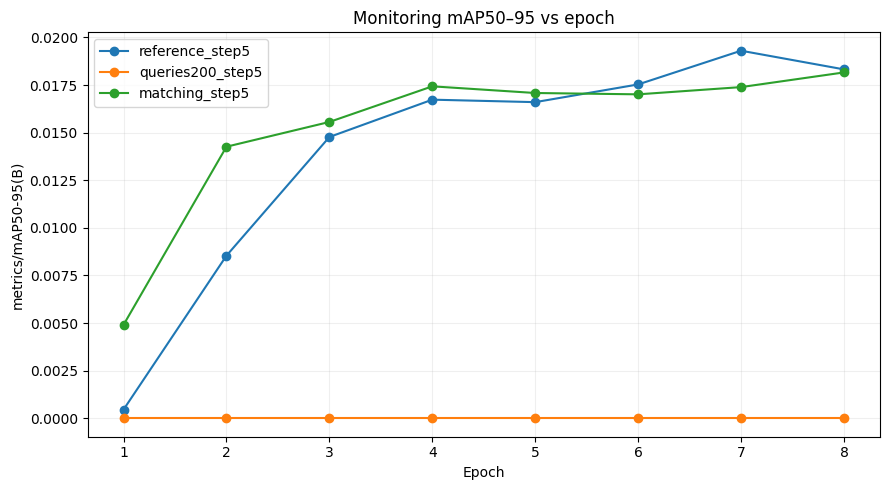

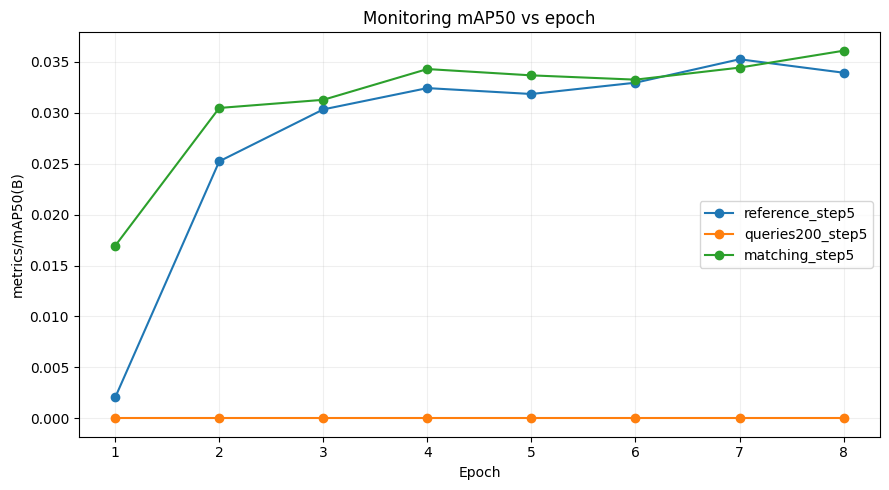

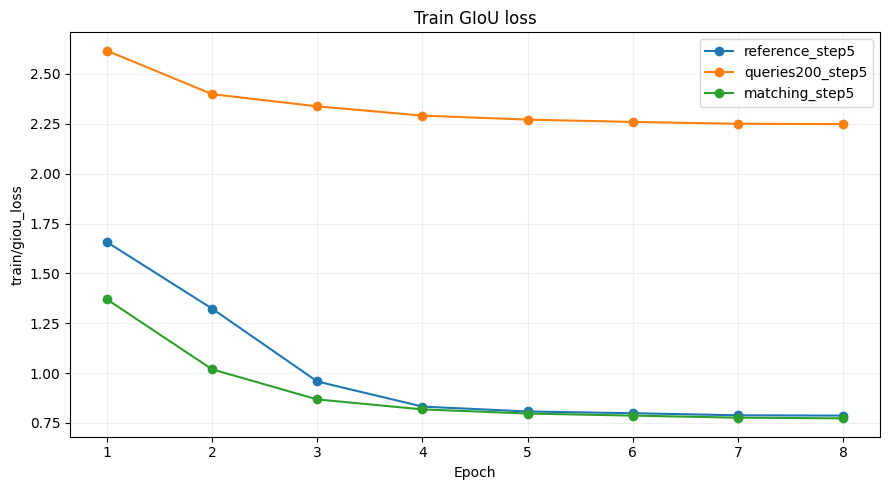

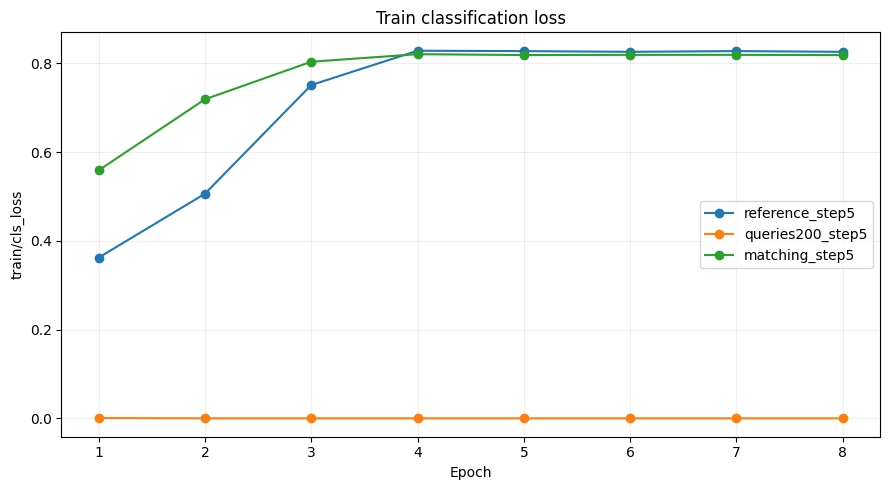

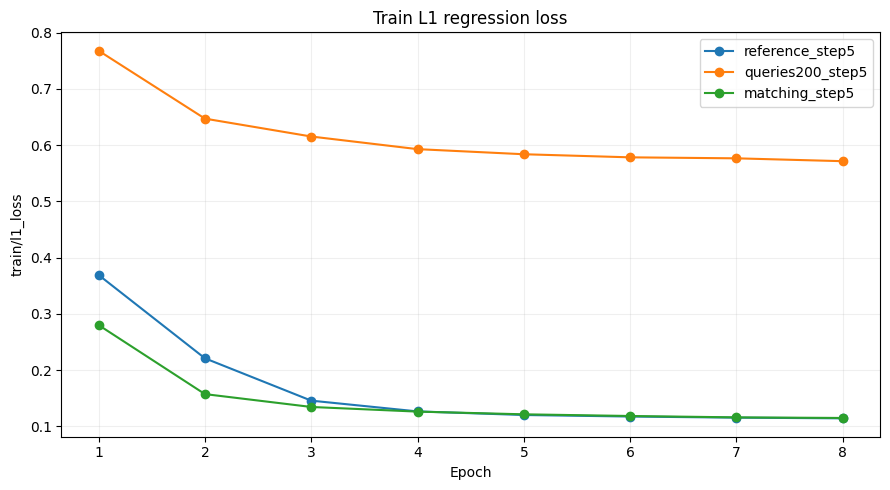

In [7]:
curves={}; rows=[]
for name in RUN_NAMES:
    p=RUNS/name/'results.csv'
    if p.is_file():
        df=pd.read_csv(p);df.columns=df.columns.str.strip();curves[name]=df
        col='metrics/mAP50-95(B)'
        if col in df:
            ix=df[col].idxmax()
            rows.append({'experiment':name,'best_monitor_epoch':int(df.loc[ix,'epoch']),
                         'best_monitor_map50_95':float(df.loc[ix,col]),
                         'queries':EXPERIMENTS[name]['queries'],**EXPERIMENTS[name]['matching']})
monitor_table=pd.DataFrame(rows)
display(monitor_table)
monitor_table.to_csv(WORK/'monitoring_comparison_step5.csv',index=False)
for metric,filename,title in [
    ('metrics/mAP50-95(B)','map50_95_training_step5.png','Monitoring mAP50–95 vs epoch'),
    ('metrics/mAP50(B)','map50_training_step5.png','Monitoring mAP50 vs epoch'),
    ('train/giou_loss','giou_loss_step5.png','Train GIoU loss'),
    ('train/cls_loss','cls_loss_step5.png','Train classification loss'),
    ('train/l1_loss','l1_loss_step5.png','Train L1 regression loss'),
]:
    fig,ax=plt.subplots(figsize=(9,5));plotted=False
    for name,df in curves.items():
        if metric not in df:continue
        ax.plot(df['epoch'],df[metric],marker='o',label=name);plotted=True
    if plotted:
        ax.set_title(title);ax.set_xlabel('Epoch');ax.set_ylabel(metric);ax.legend();ax.grid(alpha=.2)
        fig.tight_layout();fig.savefig(WORK/filename,dpi=170);plt.show()
    plt.close(fig)

## 8. COCO evaluation on **every fifth original validation frame**

One protocol for all 3: `--step 5 --tile 0 --imgsz 640 --conf 0.01`, COCO bbox AP at IoUs 0.50:0.95 and size groups. Checkpoints are trained on step5 frames in this notebook. Outputs are cached per model + evaluation settings; the runner uses a separate process to free GPU memory between models.

In [8]:
# 4. Write the SAME COCO evaluation runner as the previous notebook
# 10C. Запис окремого evaluation runner (в окремому процесі для кожної моделі)
# Runner використовує репозиторний sliced_predict і pycocotools; не тренує модель.
EVAL_SCRIPT = WORK / 'evaluate_one_rtdetr.py'
EVAL_SCRIPT.write_text(r'''import argparse, json, time
from pathlib import Path
import numpy as np
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from ultralytics import RTDETR
from src.tiled_yolo import sliced_predict
from src.data.data_utils import image_path_for
from src.yolo_baseline import MAX_DETECTIONS

p=argparse.ArgumentParser()
p.add_argument('--weights', required=True)
p.add_argument('--split-root', required=True)
p.add_argument('--out', required=True)
p.add_argument('--step',type=int,default=1)
p.add_argument('--tile',type=int,default=0)
p.add_argument('--imgsz',type=int,default=640)
p.add_argument('--conf',type=float,default=.01)
a=p.parse_args()
coco=COCO(str(Path(a.split_root)/'annotations_coco.json'))
image_ids=sorted(coco.getImgIds())[::a.step]
model=RTDETR(a.weights)
results=[]
seconds=0.0
for i,image_id in enumerate(image_ids):
    tick=time.perf_counter()
    boxes,scores,classes=sliced_predict(
        model,image_path_for(Path(a.split_root),coco.imgs[image_id]['file_name']),
        a.tile,0.2,a.imgsz,a.conf)
    elapsed=time.perf_counter()-tick
    if i: seconds+=elapsed # first image is warm-up
    for (x1,y1,x2,y2),score,cls in zip(boxes,scores,classes):
        results.append({'image_id':int(image_id),'category_id':int(cls)+1,
                        'bbox':[float(x1),float(y1),float(x2-x1),float(y2-y1)],
                        'score':float(score)})
    if (i+1)%100==0 or i+1==len(image_ids):
        print(f'Predicted {i+1}/{len(image_ids)}',flush=True)
if not results: raise RuntimeError('No predictions produced; cannot evaluate')
ev=COCOeval(coco,coco.loadRes(results),'bbox')
ev.params.imgIds=image_ids
ev.params.maxDets=[1,100,MAX_DETECTIONS]
ev.evaluate();ev.accumulate();ev.summarize()
# Extract AP from maxDet=MAX_DETECTIONS using same precision tensor as src.faster_rcnn.coco_map
pr=ev.eval['precision'][...,-1] # [IoU, recall, class, area]
def ap(a):
    v=a[a>-1]
    return float(v.mean()) if len(v) else float('nan')
metrics={
    'mAP50_95':ap(pr[:,:,:,0]),
    'AP50':ap(pr[0,:,:,0]),
    'AP75':ap(pr[5,:,:,0]),
    'AP_small':ap(pr[:,:,:,1]),
    'AP_medium':ap(pr[:,:,:,2]),
    'AP_large':ap(pr[:,:,:,3]),
    'ms_per_image':(1000*seconds/(len(image_ids)-1)) if len(image_ids)>1 else float('nan'),
    'images_evaluated':len(image_ids),
    'detections':len(results),
    'step':a.step,'tile':a.tile,'imgsz':a.imgsz,'conf':a.conf,
    'max_detections':MAX_DETECTIONS,
}
Path(a.out).write_text(json.dumps(metrics,indent=2),encoding='utf-8')
print('METRICS_JSON:',json.dumps(metrics),flush=True)
''', encoding='utf-8')
print('Prepared:',EVAL_SCRIPT)

Prepared: /kaggle/working/query_based_step5/evaluate_one_rtdetr.py
